# Model black-box: LightGBM ze strojeniem (random search), wariant z ograniczeniami monotonicznymi i porównanie z logitem

----
## 0. Importy

In [1]:
import sys, json, time, warnings; sys.path.insert(0, '..')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from lightgbm import LGBMClassifier
from src import config as cfg
from src.data import load_data, load_splits
from src.features import build_base_frame, CategoryPrep, CAT_COLS
from src.metrics import metrics, bootstrap_ci, bootstrap_gini_diff
from src.models import cross_validate_oof, summarize_folds, save_predictions, load_predictions
warnings.filterwarnings('ignore', category=UserWarning)
plt.style.use('default')

----
## 1. Dane

In [2]:
df = load_data(); splits = load_splits()
FEATURES = json.loads((cfg.TAB_DIR / '03_cechy_logit.json').read_text())['pool']
CATS = [c for c in FEATURES if c in CAT_COLS]
X = build_base_frame(df)[FEATURES]; y = df[cfg.TARGET]
tr, va = splits['train'], splits['valid']
print(len(FEATURES), 'cech, w tym kategorie:', CATS)

31 cech, w tym kategorie: ['formaWlasnosci_Symbol', 'schemat_wsk_rzis', 'pkd_sekcja']


Black-box dostaje tę samą pulę 31 cech co selekcja logitu (w tym 3 kategorie).

----
## 2. Funkcje pomocnicze

In [3]:
def make_lgbm(**params):
    base = dict(objective='binary', subsample_freq=1, random_state=cfg.SEED, n_jobs=-1, verbose=-1)
    return Pipeline([('cat', CategoryPrep(cat_cols=CATS)), ('lgbm', LGBMClassifier(**base, **params))])

def cv_eval(model):
    """
    AUC i log-loss na foldach walidacyjnych oraz AUC na foldach treningowych (kontrola przeuczenia)
    """
    auc_val, auc_fit, ll = [], [], []
    for f in splits['folds']:
        m = model.fit(X.loc[f['train']], y.loc[f['train']])
        p_val = m.predict_proba(X.loc[f['val']])[:, 1]; p_fit = m.predict_proba(X.loc[f['train']])[:, 1]
        auc_val.append(roc_auc_score(y.loc[f['val']], p_val)); auc_fit.append(roc_auc_score(y.loc[f['train']], p_fit))
        ll.append(-np.mean(y.loc[f['val']] * np.log(p_val) + (1 - y.loc[f['val']]) * np.log(1 - p_val)))
    return np.mean(auc_val), np.std(auc_val), np.mean(auc_fit), np.mean(ll)

----
## 3. Random search

In [4]:
rng = np.random.default_rng(cfg.SEED)

def sample_params():
    return dict(n_estimators=int(rng.integers(50, 601)),
                learning_rate=float(10 ** rng.uniform(-2.3, -1.3)),
                num_leaves=int(rng.integers(2, 16)),
                max_depth=int(rng.integers(1, 5)),
                min_child_samples=int(rng.integers(30, 201)),
                subsample=float(rng.uniform(0.5, 0.9)),
                colsample_bytree=float(rng.uniform(0.3, 0.8)),
                reg_lambda=float(10 ** rng.uniform(-1, 1.5)))

trials = []
for i in range(60):
    params = sample_params()
    auc, sd, auc_fit, ll = cv_eval(make_lgbm(**params))
    trials.append({**params, 'AUC CV': auc, 'odch. std': sd, 'AUC fit': auc_fit, 'luka': auc_fit - auc, 'log-loss CV': ll})
trials = pd.DataFrame(trials).sort_values('AUC CV', ascending=False)
trials.to_csv(cfg.TAB_DIR / '04_random_search.csv', index=False)

trials.head(8).round(4)

,n_estimators,learning_rate,num_leaves,max_depth,min_child_samples,subsample,colsample_bytree,reg_lambda,AUC CV,odch. std,AUC fit,luka,log-loss CV
24,348,0.0093,8,4,86,0.7083,0.5195,0.1132,0.7052,0.0344,0.8649,0.1596,0.3674
51,482,0.0219,7,1,75,0.5559,0.5389,1.1021,0.7050,0.0360,0.7877,0.0827,0.3678
53,179,0.0446,6,3,186,0.6924,0.4642,2.1807,0.7047,0.0318,0.8466,0.1418,0.3683
52,382,0.0117,5,3,92,0.6310,0.4897,5.1803,0.7040,0.0358,0.8284,0.1245,0.3673
54,579,0.0225,13,1,167,0.7131,0.6165,0.5253,0.7039,0.0291,0.7911,0.0872,0.3681
15,566,0.0249,4,2,106,0.6524,0.4508,3.7645,0.7037,0.0313,0.8706,0.1669,0.3712
58,447,0.0062,10,3,135,0.5685,0.5825,2.6982,0.7036,0.0322,0.8005,0.0970,0.3673
4,423,0.0078,12,2,109,0.5175,0.3771,5.1006,0.7035,0.0327,0.7824,0.0789,0.3678


----
## 4. Wybór konfiguracji

In [5]:
ok = trials[trials['luka'] < 0.10]

best = ok.iloc[0]

PARAMS = {k: (int(best[k]) if k in ('n_estimators', 'num_leaves', 'max_depth', 'min_child_samples') else float(best[k]))
          for k in ['n_estimators', 'learning_rate', 'num_leaves', 'max_depth', 'min_child_samples',
                    'subsample', 'colsample_bytree', 'reg_lambda']}

print('konfiguracji z luką < 0,10:', len(ok), 'z', len(trials))
print({k: round(v, 4) for k, v in PARAMS.items()})
print(f"AUC CV = {best['AUC CV']:.4f} ± {best['odch. std']:.4f}, AUC fit = {best['AUC fit']:.4f}")

konfiguracji z luką < 0,10: 29 z 60
{'n_estimators': 482, 'learning_rate': 0.0219, 'num_leaves': 7, 'max_depth': 1, 'min_child_samples': 75, 'subsample': 0.5559, 'colsample_bytree': 0.5389, 'reg_lambda': 1.1021}
AUC CV = 0.7050 ± 0.0360, AUC fit = 0.7877


----
## 5. Ograniczenia monotoniczne

In [6]:
rho = X.loc[tr, [c for c in FEATURES if c not in CATS]].corrwith(y.loc[tr], method='spearman')

MONO = [0 if (c in CATS or c in cfg.U_SHAPE) else int(np.sign(rho[c])) for c in FEATURES]

print('ograniczenia: +1 (PD rośnie):', MONO.count(1), '| -1 (PD maleje):', MONO.count(-1), '| bez:', MONO.count(0))
variants = {'LightGBM': make_lgbm(**PARAMS),
            'LightGBM monotoniczny': make_lgbm(**PARAMS, monotone_constraints=MONO, monotone_constraints_method='advanced')}

cv = {}
for name, model in variants.items():
    oof, folds = cross_validate_oof(model, X, y, splits)
    cv[name] = (oof, folds)
pd.concat({n: summarize_folds(f) for n, (o, f) in cv.items()}, axis=1).round(4)

ograniczenia: +1 (PD rośnie): 7 | -1 (PD maleje): 20 | bez: 4


LightGBM           LightGBM monotoniczny          
          średnia odch. std               średnia odch. std
AUC        0.7050    0.0403                0.7082    0.0398
Gini       0.4100    0.0805                0.4164    0.0797
KS         0.3419    0.0416                0.3492    0.0528
PR-AUC     0.2914    0.0367                0.2931    0.0393
log-loss   0.3678    0.0144                0.3680    0.0152
Brier      0.1110    0.0046                0.1112    0.0047

**Wnioski:** kierunek ograniczeń bierzemy ze znaku korelacji Spearmana na train (7 cech „PD rośnie”, 20 „PD maleje”, 4 bez ograniczeń: kategorie i cecha z kształtem U). Ograniczenia nie pogarszają AUC na CV (0,708 vs 0,705).

----
## 6. Porównanie z logitem (valid)

In [7]:
logit_pred = load_predictions('logit').set_index('id')
p_logit_va = logit_pred[logit_pred.zbior == 'valid'].loc[va, 'p']
fitted = {n: m.fit(X.loc[tr], y.loc[tr]) for n, m in variants.items()}
rows = {'logit (krok 03)': metrics(y.loc[va], p_logit_va)}
for n, m in fitted.items():
    rows[n] = metrics(y.loc[va], m.predict_proba(X.loc[va])[:, 1])
comp = pd.DataFrame(rows).T.drop(columns='n')
comp.insert(0, 'AUC CV', [pd.read_csv(cfg.TAB_DIR / '03_cv_foldy.csv')['AUC'].mean()] + [summarize_folds(cv[n][1]).loc['AUC', 'średnia'] for n in fitted])
comp.insert(1, 'AUC train', [np.nan] + [roc_auc_score(y.loc[tr], m.predict_proba(X.loc[tr])[:, 1]) for m in fitted.values()])
comp.to_csv(cfg.TAB_DIR / '04_porownanie_valid.csv')
display(comp.round(4))
for n, m in fitted.items():
    booster = m.named_steps['lgbm'].booster_
    print(f'{n}: drzew = {booster.num_trees()}, liści łącznie = {booster.trees_to_dataframe().query("left_child.isna()").shape[0]}, '
          f'cech użytych = {(m.named_steps["lgbm"].feature_importances_ > 0).sum()} z {len(FEATURES)}')

,AUC CV,AUC train,DR,średnie PD,AUC,Gini,KS,PR-AUC,log-loss,Brier,ECE,ACE
logit (krok 03),0.7178,NaN,0.1375,0.1426,0.7481,0.4962,0.4446,0.3416,0.3542,0.1064,0.0436,0.0395
LightGBM,0.7050,0.7775,0.1375,0.1422,0.7666,0.5331,0.4220,0.3811,0.3460,0.1038,0.0167,0.0343
LightGBM monotoniczny,0.7082,0.7685,0.1375,0.1430,0.7585,0.5170,0.4061,0.3520,0.3482,0.1046,0.0227,0.0328


LightGBM: drzew = 482, liści łącznie = 964, cech użytych = 31 z 31
LightGBM monotoniczny: drzew = 482, liści łącznie = 964, cech użytych = 29 z 31


**Wnioski:** na valid oba warianty LightGBM mają wyższe AUC (0,758–0,767) niż logit (0,748), ale na CV logit był lepszy (0,718 vs 0,708). Różnice zależą więc od próby. Model monotoniczny korzysta z 29 z 31 cech.

----
## 7. Istotność różnicy (bootstrap)

In [8]:
for n, m in fitted.items():
    p = m.predict_proba(X.loc[va])[:, 1]
    d, (lo, hi) = bootstrap_gini_diff(y.loc[va], p_logit_va.values, p)
    print(f'{n} - logit: ΔGini = {d:+.3f}, 95% CI [{lo:+.3f}; {hi:+.3f}]')
bootstrap_ci(y.loc[va], fitted['LightGBM'].predict_proba(X.loc[va])[:, 1]).round(3)

LightGBM - logit: ΔGini = +0.037, 95% CI [-0.020; +0.101]
LightGBM monotoniczny - logit: ΔGini = +0.021, 95% CI [-0.032; +0.072]


,"CI 2,5%","CI 97,5%"
AUC,0.701,0.828
Gini,0.403,0.657
KS,0.343,0.556
PR-AUC,0.280,0.508


**Wnioski:** przedziały ufności ΔGini zawierają 0 (LightGBM +0,037 [−0,020; +0,101], monotoniczny +0,021 [−0,032; +0,072]), więc na valid przewaga black-boxa nad logitem nie jest istotna statystycznie.

----
## 8. Ważność cech (gain)

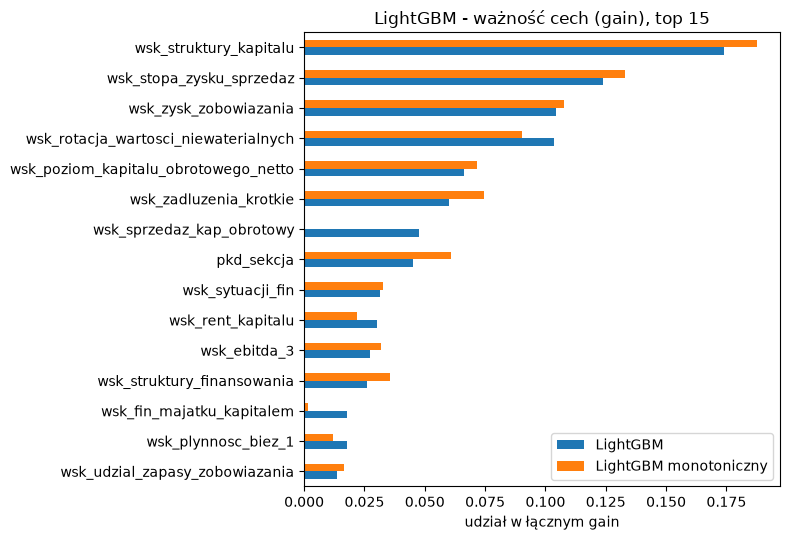

In [9]:
imp = pd.DataFrame({n: pd.Series(m.named_steps['lgbm'].booster_.feature_importance('gain'), index=FEATURES)
                    for n, m in fitted.items()})
imp = (imp / imp.sum()).sort_values('LightGBM', ascending=False)
ax = imp.head(15)[::-1].plot.barh(figsize=(8, 5.5)); ax.set_xlabel('udział w łącznym gain')
ax.set_title('LightGBM - ważność cech (gain), top 15'); plt.tight_layout()
plt.savefig(cfg.FIG_DIR / '04_waznosc_gain.png', dpi=150); plt.show()

----
## 9. Zapis wyników

In [10]:
(cfg.ROOT / 'outputs' / 'models').mkdir(parents=True, exist_ok=True)
for n, key in [('LightGBM', 'lgbm'), ('LightGBM monotoniczny', 'lgbm_mono')]:
    m = fitted[n]
    save_predictions(key, cv[n][0], m.predict_proba(X.loc[va])[:, 1], m.predict_proba(X.loc[splits['test']])[:, 1], splits)
    joblib.dump({'model': m, 'features': FEATURES, 'params': PARAMS}, cfg.ROOT / 'outputs' / 'models' / f'{key}.joblib')
(cfg.TAB_DIR / '04_parametry.json').write_text(json.dumps({'params': PARAMS, 'monotone': dict(zip(FEATURES, MONO))}, indent=1))

1328

**Wnioski:** do dalszych kroków przechodzi wariant monotoniczny (`lgbm_mono`): ma praktycznie tę samą skuteczność, a jego zależności są zgodne z intuicją ekonomiczną.